# 🌿 Multispectral U-Net for Precision Agriculture & Weed Mapping
**Authors:** Rishi Kumar & Harshit  
**Institution:** Indian Institute of Information Technology, Senapati, Manipur (ECE Department)  

### Project Overview
This notebook implements a custom **1.94M-parameter Lightweight U-Net** designed for pixel-wise semantic segmentation of aerial multispectral imagery. The system classifies agricultural field pixels into three distinct categories:
1. **Background / Soil** (Class 0)
2. **Crops (Sugar Beets)** (Class 1)
3. **Weeds** (Class 2)

The pipeline integrates 6-channel multispectral inputs (Blue, Green, Red, Red-Edge, NIR, and computed NDVI indices) based on the foundational **WeedMap** benchmark (*Sa et al., 2018*).

In [2]:
import os
import glob
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Automatically find RedEdge.zip (or RedEdge.zip.zip) in My Drive
matches = glob.glob("/content/drive/MyDrive/RedEdge*.zip")
if not matches:
    raise FileNotFoundError("Could not find RedEdge.zip in My Drive! Make sure the upload finished.")
ZIP_PATH = matches[0]
print("Found zip file at:", ZIP_PATH)

# 3. Extract to Colab's fast local SSD (/content/dataset) in ~10 seconds
EXTRACT_DIR = "/content/dataset"
if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    print("Extracting to Colab local SSD...")
    !unzip -q "{ZIP_PATH}" -d "{EXTRACT_DIR}"
    print("Extraction complete!")

# 4. Locate folder '000'
BASE_DIR = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if all(f in dirs for f in ["000", "001", "002", "003", "004"]):
        BASE_DIR = root
        break

SAVE_DIR = "/content/drive/MyDrive/WeedMap_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Confirmed BASE_DIR:", BASE_DIR)
print("Subfolders found:  ", sorted(os.listdir(BASE_DIR)))

Mounted at /content/drive
Found zip file at: /content/drive/MyDrive/RedEdge.zip.zip
Extracting to Colab local SSD...
Extraction complete!
Confirmed BASE_DIR: /content/dataset/RedEdge
Subfolders found:   ['000', '001', '002', '003', '004']


---
### 1. Configuration & Multispectral Dataset Pipeline
This section defines the configuration parameters, spectral bands (`SELECTED_CHANNELS = ["B", "G", "R", "RE", "NIR", "NDVI"]`), and the custom PyTorch `Dataset` class (`WeedMapDataset`) which handles mask polarity correction (`mask == 0` for valid field pixels vs. invalid padding) and data augmentation.

### 2. Lightweight U-Net Architecture (~1.94M Parameters)
We define a symmetric encoder-decoder network optimized for edge and cloud deployment.
- **Encoder (Contracting Path):** Uses max-pooling (`MaxPool2d`) and dual convolution blocks (`DoubleConv`) with Batch Normalization to extract hierarchical spatial features.
- **Decoder (Expanding Path):** Uses transposed convolutions (`ConvTranspose2d`) and skip connections with bilinear interpolation to recover fine boundary details for narrow weed leaves.
- **Base Filters:** Set to $f=16$ to maintain an ultra-lightweight footprint (~1.94M parameters).

In [5]:
import os
import time
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, average_precision_score

# =====================================================================
# 1. CONFIGURATION
# =====================================================================
TRAIN_FOLDERS = ["000", "001", "002", "004"]
TEST_FOLDERS  = ["003"]

# Spectral configurations you can test (change this list & re-run Cell 2 to compare!):
#   ["NDVI"]                             -> 1 channel  (Single Vegetation Index)
#   ["R", "G", "B"]                      -> 3 channels (Standard RGB)
#   ["R", "G", "NIR"]                    -> 3 channels (Compact Multispectral)
#   ["B", "G", "R", "RE", "NIR"]         -> 5 channels (Raw RedEdge-M Bands)
#   ["B", "G", "R", "RE", "NIR", "NDVI"] -> 6 channels (Full Multispectral Stack)
SELECTED_CHANNELS = ["B", "G", "R", "RE", "NIR", "NDVI"]

# "valid_field" = all tiles containing valid field pixels (mask == 0)
# "veg"         = only tiles containing crop/weed vegetation (iMap > 0)
FILTER_MODE = "valid_field"

BATCH_SIZE = 16
EPOCHS = 25
LR = 1e-3
IGNORE_INDEX = 255
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# =====================================================================
# 2. DATASET LOADER (Corrected Mask Polarity: mask==0 is Valid, mask>0 is Invalid!)
# =====================================================================
class WeedMapDataset(Dataset):
    def __init__(self, base_dir, folders, channels, filter_mode="valid_field", is_train=True):
        self.channels = channels
        self.is_train = is_train
        self.samples = []

        for folder in folders:
            folder_path = os.path.join(base_dir, folder)
            mask_dir = os.path.join(folder_path, "mask")
            gt_dir   = os.path.join(folder_path, "groundtruth")
            tile_dir = os.path.join(folder_path, "tile")

            mask_files = sorted([f for f in os.listdir(mask_dir) if f.lower().endswith(".png")])
            for mf in mask_files:
                frame_name = os.path.splitext(mf)[0]
                mask_path = os.path.join(mask_dir, mf)
                imap_path = os.path.join(gt_dir, f"{folder}_{frame_name}_GroundTruth_iMap.png")

                if filter_mode == "veg":
                    imap_arr = np.array(Image.open(imap_path))
                    is_valid = np.any(imap_arr > 0)
                else:
                    # In ETH Zurich RedEdge, mask == 0 is valid field and mask > 0 is invalid padding!
                    mask_arr = np.array(Image.open(mask_path))
                    is_valid = np.any(mask_arr == 0)

                if is_valid:
                    ch_paths = [os.path.join(tile_dir, ch, mf) for ch in channels]
                    self.samples.append((ch_paths, mask_path, imap_path))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ch_paths, mask_path, imap_path = self.samples[idx]

        # 1. Load and stack spectral channels -> (C, 360, 480) normalized to [0, 1]
        band_list = []
        for cp in ch_paths:
            img = np.array(Image.open(cp), dtype=np.float32) / 255.0
            if img.ndim == 3:
                band_list.append(np.transpose(img, (2, 0, 1)))
            else:
                band_list.append(img[np.newaxis, :, :])
        x = np.concatenate(band_list, axis=0)

        # 2. Load 16-bit ground-truth iMap and 8-bit binary validity mask
        imap = np.array(Image.open(imap_path), dtype=np.int64)
        mask = np.array(Image.open(mask_path))

        # 3. Remap: 0 -> 0 (Bg), 10000 -> 1 (Crop), 2 -> 2 (Weed)
        target = np.zeros_like(imap, dtype=np.int64)
        target[imap == 10000] = 1
        target[imap == 2]     = 2

        # 4. Mask out invalid border regions (where mask > 0 -> IGNORE_INDEX)
        target[mask > 0] = IGNORE_INDEX

        # 5. Horizontal flip augmentation during training
        if self.is_train and np.random.rand() > 0.5:
            x = np.flip(x, axis=2).copy()
            target = np.flip(target, axis=1).copy()

        return torch.from_numpy(x), torch.from_numpy(target)


# =====================================================================
# 3. LIGHTWEIGHT U-NET ARCHITECTURE (~1.9M Parameters)
# =====================================================================
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)


class LightweightUNet(nn.Module):
    def __init__(self, in_channels, num_classes=3, base_filters=16):
        super().__init__()
        f = base_filters  # [16, 32, 64, 128, 256]
        self.enc1 = DoubleConv(in_channels, f)
        self.enc2 = DoubleConv(f, f * 2)
        self.enc3 = DoubleConv(f * 2, f * 4)
        self.enc4 = DoubleConv(f * 4, f * 8)
        self.pool = nn.MaxPool2d(2, 2)

        self.bottleneck = DoubleConv(f * 8, f * 16)

        self.up4  = nn.ConvTranspose2d(f * 16, f * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(f * 16, f * 8)
        self.up3  = nn.ConvTranspose2d(f * 8, f * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(f * 8, f * 4)
        self.up2  = nn.ConvTranspose2d(f * 4, f * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(f * 4, f * 2)
        self.up1  = nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(f * 2, f)

        self.out_conv = nn.Conv2d(f, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        if d4.shape != e4.shape:
            d4 = nn.functional.interpolate(d4, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = self.dec4(torch.cat([e4, d4], dim=1))

        d3 = self.up3(d4)
        if d3.shape != e3.shape:
            d3 = nn.functional.interpolate(d3, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([e3, d3], dim=1))

        d2 = self.up2(d3)
        if d2.shape != e2.shape:
            d2 = nn.functional.interpolate(d2, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([e2, d2], dim=1))

        d1 = self.up1(d2)
        if d1.shape != e1.shape:
            d1 = nn.functional.interpolate(d1, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([e1, d1], dim=1))

        return self.out_conv(d1)


# =====================================================================
# 4. EVALUATION & RISK METRICS (F1, IoU, ROC-AUC, PR-AUC, Crop<->Weed)
# =====================================================================
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    conf_matrix = np.zeros((3, 3), dtype=np.int64)
    all_weed_probs = []
    all_weed_true  = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        probs  = torch.softmax(logits, dim=1)
        preds  = torch.argmax(probs, dim=1)

        valid_mask = (y != IGNORE_INDEX)
        y_valid    = y[valid_mask].cpu().numpy()
        p_valid    = preds[valid_mask].cpu().numpy()
        w_prob     = probs[:, 2, :, :][valid_mask].cpu().numpy()

        idx = 3 * y_valid + p_valid
        counts = np.bincount(idx, minlength=9).reshape(3, 3)
        conf_matrix += counts

        all_weed_probs.append(w_prob[::10])
        all_weed_true.append((y_valid[::10] == 2).astype(np.int32))

    tp_w = conf_matrix[2, 2]
    fp_w = conf_matrix[0, 2] + conf_matrix[1, 2]
    fn_w = conf_matrix[2, 0] + conf_matrix[2, 1]

    weed_iou = tp_w / (tp_w + fp_w + fn_w + 1e-8)
    weed_f1  = (2 * tp_w) / (2 * tp_w + fp_w + fn_w + 1e-8)

    # Also compute Crop F1 for complete reporting
    tp_c = conf_matrix[1, 1]
    fp_c = conf_matrix[0, 1] + conf_matrix[2, 1]
    fn_c = conf_matrix[1, 0] + conf_matrix[1, 2]
    crop_f1 = (2 * tp_c) / (2 * tp_c + fp_c + fn_c + 1e-8)

    # Risk-oriented confusion measures
    total_true_crop = conf_matrix[1, :].sum()
    risk_crop_to_weed = conf_matrix[1, 2] / (total_true_crop + 1e-8)

    total_true_weed = conf_matrix[2, :].sum()
    risk_weed_to_crop = conf_matrix[2, 1] / (total_true_weed + 1e-8)

    y_true_bin = np.concatenate(all_weed_true)
    y_prob_bin = np.concatenate(all_weed_probs)
    roc_auc = roc_auc_score(y_true_bin, y_prob_bin)
    pr_auc  = average_precision_score(y_true_bin, y_prob_bin)

    return {
        "Weed_F1": weed_f1,
        "Crop_F1": crop_f1,
        "Weed_IoU": weed_iou,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Risk_Crop->Weed": risk_crop_to_weed,
        "Risk_Weed->Crop": risk_weed_to_crop,
        "Conf_Matrix": conf_matrix
    }


# =====================================================================
# 5. RUN TRAINING
# =====================================================================
ch_tag = "_".join(SELECTED_CHANNELS)
print(f"\n--- Risk-Aware Lightweight U-Net (Corrected Mask Polarity) ---")
print(f"Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Spectral Input ({len(SELECTED_CHANNELS)}ch): {SELECTED_CHANNELS} | Filter: '{FILTER_MODE}'")

train_ds = WeedMapDataset(BASE_DIR, TRAIN_FOLDERS, SELECTED_CHANNELS, filter_mode=FILTER_MODE, is_train=True)
test_ds  = WeedMapDataset(BASE_DIR, TEST_FOLDERS,  SELECTED_CHANNELS, filter_mode=FILTER_MODE, is_train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

model = LightweightUNet(in_channels=len(SELECTED_CHANNELS), num_classes=3, base_filters=16).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Loaded {len(train_ds)} train tiles, {len(test_ds)} test tiles | Params: {total_params:,}\n")

# Paper's exact RedEdge class weights: [bg=0.0638, crop=1.0, weed=1.6817]
class_weights = torch.tensor([0.0638, 1.0, 1.6817], dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights, ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

best_f1 = 0.0
save_path = os.path.join(SAVE_DIR, f"best_unet_{ch_tag}.pth")

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    t0 = time.time()

    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    metrics = evaluate(model, test_loader, DEVICE)
    elapsed = time.time() - t0

    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} ({elapsed:.1f}s) | "
        f"Loss: {avg_loss:.4f} | "
        f"Weed F1: {metrics['Weed_F1']:.4f} | "
        f"Crop F1: {metrics['Crop_F1']:.4f} | "
        f"IoU: {metrics['Weed_IoU']:.4f} | "
        f"ROC-AUC: {metrics['ROC_AUC']:.4f} | "
        f"PR-AUC: {metrics['PR_AUC']:.4f} | "
        f"Crop->Weed: {metrics['Risk_Crop->Weed']*100:.2f}% | "
        f"Weed->Crop: {metrics['Risk_Weed->Crop']*100:.2f}%"
    )

    if metrics["Weed_F1"] > best_f1:
        best_f1 = metrics["Weed_F1"]
        torch.save(model.state_dict(), save_path)

print(f"\nTraining Complete! Best Weed F1 ({ch_tag}): {best_f1:.4f} | Saved to: {save_path}")


--- Risk-Aware Lightweight U-Net (Corrected Mask Polarity) ---
Device: cuda (Tesla T4)
Spectral Input (6ch): ['B', 'G', 'R', 'RE', 'NIR', 'NDVI'] | Filter: 'valid_field'
Loaded 455 train tiles, 102 test tiles | Params: 1,943,043

Epoch 01/25 (17.9s) | Loss: 0.6498 | Weed F1: 0.2586 | Crop F1: 0.0000 | IoU: 0.1485 | ROC-AUC: 0.9269 | PR-AUC: 0.2505 | Crop->Weed: 99.51% | Weed->Crop: 0.00%
Epoch 02/25 (19.8s) | Loss: 0.4797 | Weed F1: 0.4930 | Crop F1: 0.6989 | IoU: 0.3272 | ROC-AUC: 0.9780 | PR-AUC: 0.7703 | Crop->Weed: 10.01% | Weed->Crop: 1.75%
Epoch 03/25 (18.4s) | Loss: 0.4100 | Weed F1: 0.1884 | Crop F1: 0.4441 | IoU: 0.1040 | ROC-AUC: 0.9389 | PR-AUC: 0.6756 | Crop->Weed: 2.04% | Weed->Crop: 9.11%
Epoch 04/25 (17.7s) | Loss: 0.3538 | Weed F1: 0.4210 | Crop F1: 0.5926 | IoU: 0.2666 | ROC-AUC: 0.9318 | PR-AUC: 0.5972 | Crop->Weed: 0.70% | Weed->Crop: 15.69%
Epoch 05/25 (19.1s) | Loss: 0.3268 | Weed F1: 0.4896 | Crop F1: 0.6316 | IoU: 0.3241 | ROC-AUC: 0.9685 | PR-AUC: 0.7223 | Crop

---
### Final Evaluation, Metrics Report, and Visualizations
This final block loads the best saved checkpoint, evaluates performance on Test Field 003, prints the complete risk-aware metric breakdown (F1 scores, IoU, ROC-AUC, PR-AUC, Herbicide Damage Risk, and Missed Weed Escapes), and renders high-resolution side-by-side comparisons of the False-Color composite, NDVI channel, Ground Truth mask, and the Lightweight U-Net predictions, saving the output plot to Google Drive.

 FINAL TEST EVALUATION (Field 003) | Model: best_unet_B_G_R_RE_NIR_NDVI.pth
  Weed F1 Score          : 68.31%  (0.6831)
  Crop F1 Score          : 81.43%  (0.8143)
  Weed IoU (Jaccard)     : 51.87%  (0.5187)
  Weed ROC-AUC           : 0.9827
  Weed PR-AUC            : 0.7700
------------------------------------------------------------------
   Herbicide Damage Risk (Crop -> Weed) : 0.80%
  Missed Weed Escape    (Weed -> Crop) : 6.63%



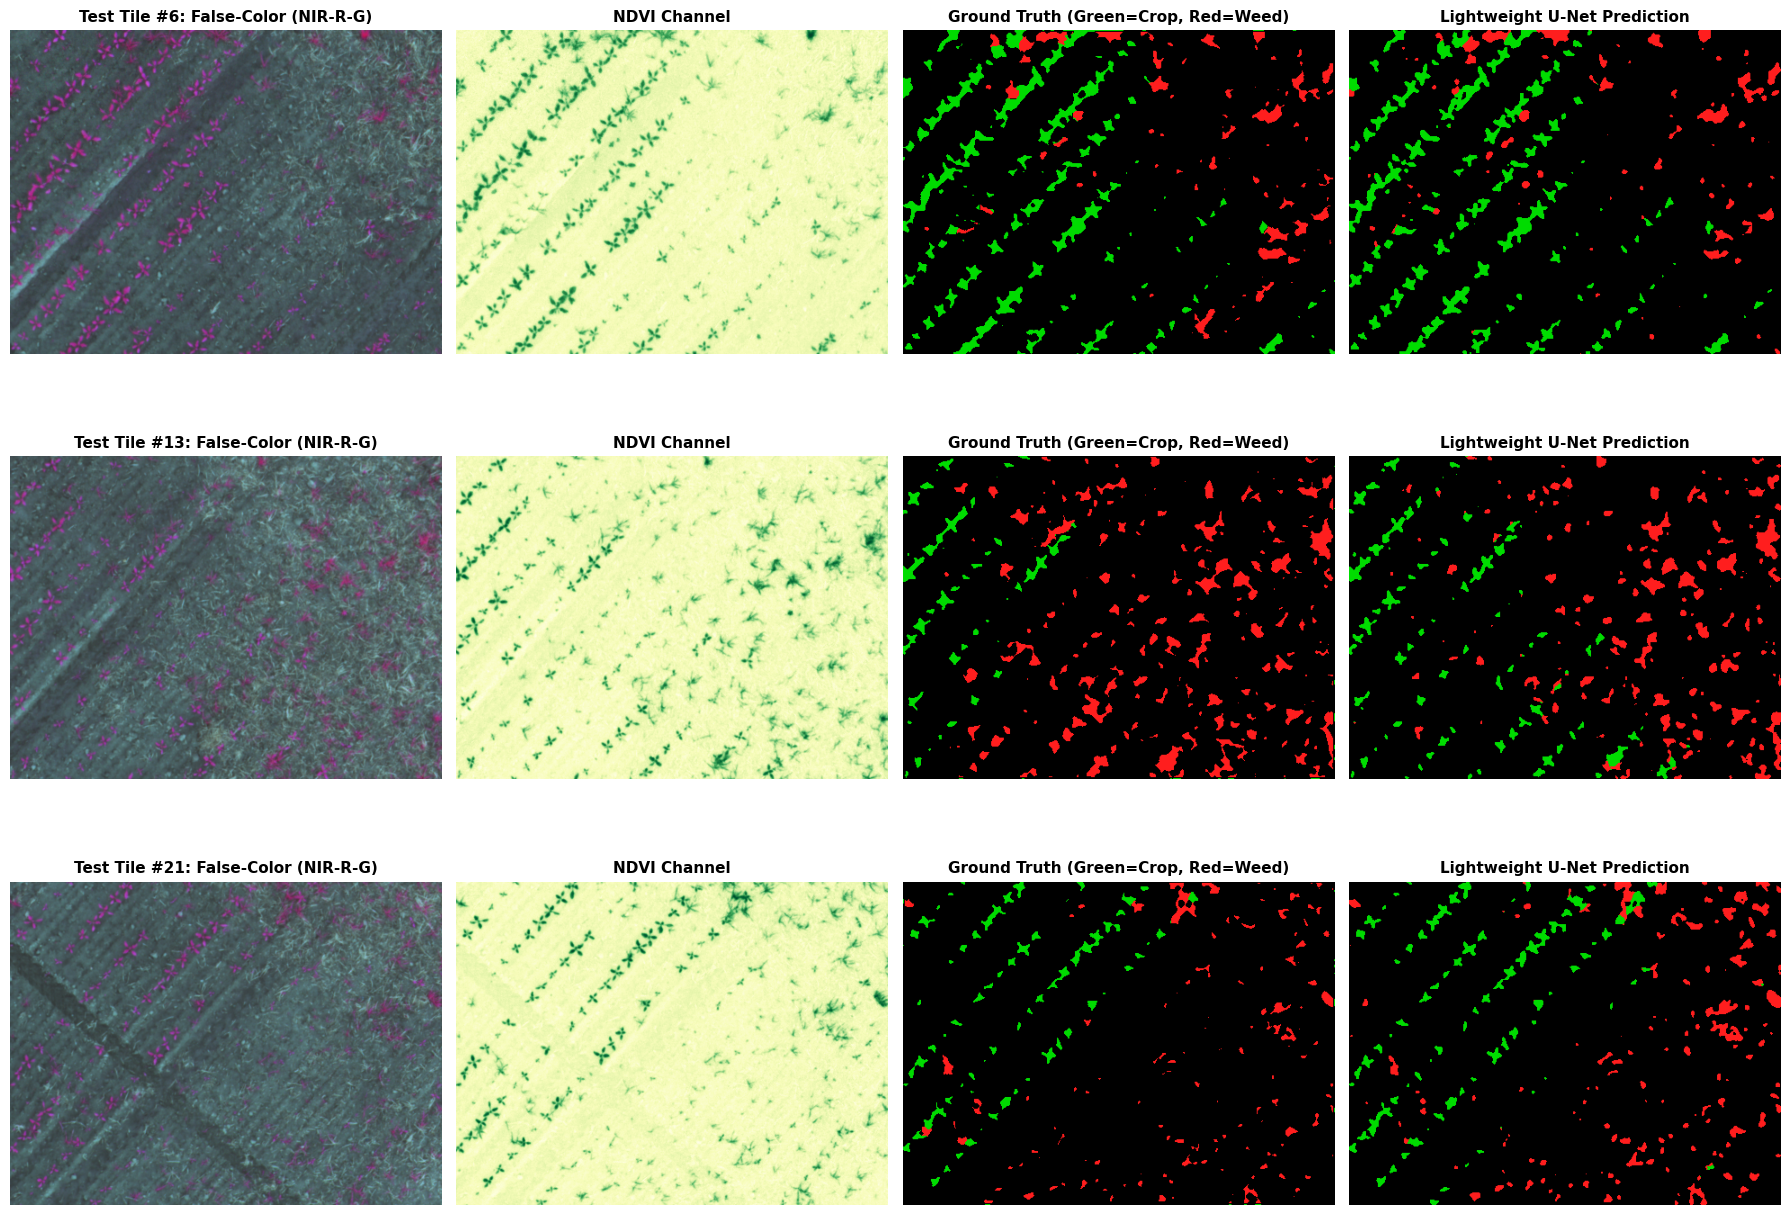

Saved high-res prediction plot to Google Drive: /content/drive/MyDrive/WeedMap_Models/weedmap_predictions_003.png


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Load your best saved checkpoint (Epoch 11: Weed F1 = 0.6831, Crop F1 = 0.8143)
best_model = LightweightUNet(in_channels=len(SELECTED_CHANNELS), num_classes=3, base_filters=16).to(DEVICE)
best_model.load_state_dict(torch.load(save_path, map_location=DEVICE))
best_model.eval()

# 2. Run final evaluation on Test Field 003
final_metrics = evaluate(best_model, test_loader, DEVICE)
cm = final_metrics["Conf_Matrix"]

print("==================================================================")
print(f" FINAL TEST EVALUATION (Field 003) | Model: {os.path.basename(save_path)}")
print("==================================================================")
print(f"  Weed F1 Score          : {final_metrics['Weed_F1']*100:.2f}%  ({final_metrics['Weed_F1']:.4f})")
print(f"  Crop F1 Score          : {final_metrics['Crop_F1']*100:.2f}%  ({final_metrics['Crop_F1']:.4f})")
print(f"  Weed IoU (Jaccard)     : {final_metrics['Weed_IoU']*100:.2f}%  ({final_metrics['Weed_IoU']:.4f})")
print(f"  Weed ROC-AUC           : {final_metrics['ROC_AUC']:.4f}")
print(f"  Weed PR-AUC            : {final_metrics['PR_AUC']:.4f}")
print("------------------------------------------------------------------")
print(f"   Herbicide Damage Risk (Crop -> Weed) : {final_metrics['Risk_Crop->Weed']*100:.2f}%")
print(f"  Missed Weed Escape    (Weed -> Crop) : {final_metrics['Risk_Weed->Crop']*100:.2f}%")
print("==================================================================\n")

# 3. Helper to colorize segmentation maps: Black=Bg/Invalid, Green=Crop(1), Red=Weed(2)
def colorize_mask(arr):
    h, w = arr.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    rgb[arr == 1] = [0, 220, 0]    # Green = Crop
    rgb[arr == 2] = [255, 30, 30]  # Red   = Weed
    rgb[arr == IGNORE_INDEX] = [40, 40, 40]  # Dark gray = Invalid border
    return rgb

# 4. Find test tiles with rich both Crop and Weed presence to visualize
vis_indices = []
for idx in range(len(test_ds)):
    _, target = test_ds[idx]
    t_np = target.numpy()
    if np.sum(t_np == 1) > 3000 and np.sum(t_np == 2) > 3000:
        vis_indices.append(idx)
    if len(vis_indices) == 3:
        break

fig, axes = plt.subplots(len(vis_indices), 4, figsize=(18, 4.5 * len(vis_indices)))
if len(vis_indices) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, idx in enumerate(vis_indices):
    x_tensor, y_tensor = test_ds[idx]
    with torch.no_grad():
        logits = best_model(x_tensor.unsqueeze(0).to(DEVICE))
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

    y_np = y_tensor.numpy()
    pred_masked = pred.copy()
    pred_masked[y_np == IGNORE_INDEX] = IGNORE_INDEX

    # Extract NIR, Red, Green for False-Color Composite (or available channels)
    x_np = x_tensor.numpy()
    ch_map = {c: i for i, c in enumerate(SELECTED_CHANNELS)}
    if all(k in ch_map for k in ["NIR", "R", "G"]):
        fc = np.stack([x_np[ch_map["NIR"]], x_np[ch_map["R"]], x_np[ch_map["G"]]], axis=-1)
        fc_title = f"Test Tile #{idx}: False-Color (NIR-R-G)"
    else:
        fc = x_np[0]
        fc_title = f"Test Tile #{idx}: Band {SELECTED_CHANNELS[0]}"

    ndvi_img = x_np[ch_map["NDVI"]] if "NDVI" in ch_map else x_np[-1]

    axes[row, 0].imshow(np.clip(fc, 0, 1))
    axes[row, 0].set_title(fc_title, fontsize=11, fontweight="bold")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(ndvi_img, cmap="YlGn")
    axes[row, 1].set_title("NDVI Channel", fontsize=11, fontweight="bold")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(colorize_mask(y_np))
    axes[row, 2].set_title("Ground Truth (Green=Crop, Red=Weed)", fontsize=11, fontweight="bold")
    axes[row, 2].axis("off")

    axes[row, 3].imshow(colorize_mask(pred_masked))
    axes[row, 3].set_title("Lightweight U-Net Prediction", fontsize=11, fontweight="bold")
    axes[row, 3].axis("off")

plt.tight_layout()
plot_path = os.path.join(SAVE_DIR, "weedmap_predictions_003.png")
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved high-res prediction plot to Google Drive: {plot_path}")

---
### Confusion Matrix & Per-Class Metric Analysis
This block calculates the row-normalized percentage confusion matrix and the detailed per-class summary table (Precision, Recall, F1 Score, and Jaccard IoU) for Test Field 003, exporting the dual-panel figure (`confusion_matrix_003.png`) directly to Google Drive.

 3x3 PIXEL CONFUSION MATRIX (Test Field 003 - Valid Field Pixels Only)
True \ Predicted   |   Background (0) |         Crop (1) |         Weed (2)
--------------------------------------------------------------------------
Background (0)     |       11,570,187 |          257,561 |          172,665
Crop (1)           |           11,408 |          651,452 |            5,367
Weed (2)           |           50,339 |           22,799 |          270,661



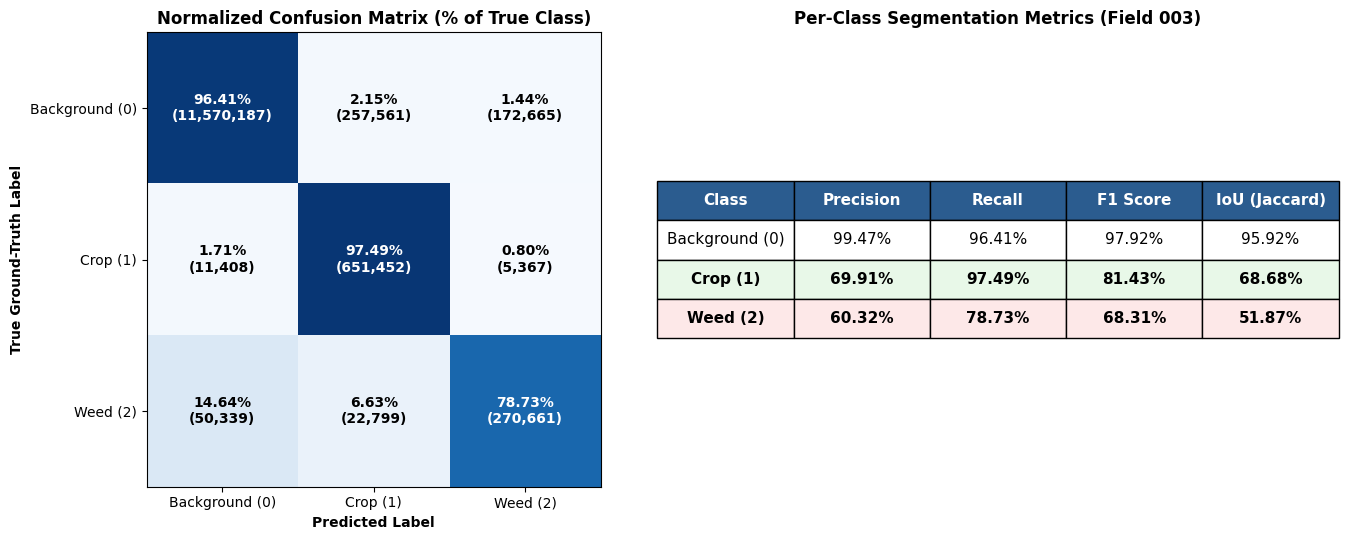

Saved Confusion Matrix figure to Google Drive: /content/drive/MyDrive/WeedMap_Models/confusion_matrix_003.png


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Use the confusion matrix already computed in Cell 3 (final_metrics["Conf_Matrix"])
cm = final_metrics["Conf_Matrix"]
class_names = ["Background (0)", "Crop (1)", "Weed (2)"]

# Row-normalize to show percentage of each true class predicted into each category
cm_norm = cm.astype(np.float64) / (cm.sum(axis=1, keepdims=True) + 1e-8) * 100.0

print("==========================================================================")
print(" 3x3 PIXEL CONFUSION MATRIX (Test Field 003 - Valid Field Pixels Only)")
print("==========================================================================")
print(f"{'True \\ Predicted':<18} | {'Background (0)':>16} | {'Crop (1)':>16} | {'Weed (2)':>16}")
print("-" * 74)
for i, cname in enumerate(class_names):
    print(f"{cname:<18} | {cm[i,0]:16,d} | {cm[i,1]:16,d} | {cm[i,2]:16,d}")
print("==========================================================================\n")

# Plot Raw Counts and Row-Normalized Percentages side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: Normalized Percentages
im1 = axes[0].imshow(cm_norm, cmap="Blues", vmin=0, vmax=100)
axes[0].set_title("Normalized Confusion Matrix (% of True Class)", fontsize=12, fontweight="bold")
axes[0].set_xticks([0, 1, 2]); axes[0].set_xticklabels(class_names, fontsize=10)
axes[0].set_yticks([0, 1, 2]); axes[0].set_yticklabels(class_names, fontsize=10)
axes[0].set_xlabel("Predicted Label", fontweight="bold")
axes[0].set_ylabel("True Ground-Truth Label", fontweight="bold")

for i in range(3):
    for j in range(3):
        color = "white" if cm_norm[i, j] > 50 else "black"
        axes[0].text(j, i, f"{cm_norm[i, j]:.2f}%\n({cm[i, j]:,})",
                     ha="center", va="center", color=color, fontsize=10, fontweight="bold")

# Panel 2: Per-Class Precision, Recall, F1, IoU Summary Table
axes[1].axis("off")
axes[1].set_title("Per-Class Segmentation Metrics (Field 003)", fontsize=12, fontweight="bold")

table_data = []
for c in range(3):
    tp = cm[c, c]
    fp = cm[:, c].sum() - tp
    fn = cm[c, :].sum() - tp
    prec = tp / (tp + fp + 1e-8) * 100
    rec  = tp / (tp + fn + 1e-8) * 100
    f1   = (2 * tp) / (2 * tp + fp + fn + 1e-8) * 100
    iou  = tp / (tp + fp + fn + 1e-8) * 100
    table_data.append([class_names[c], f"{prec:.2f}%", f"{rec:.2f}%", f"{f1:.2f}%", f"{iou:.2f}%"])

col_labels = ["Class", "Precision", "Recall", "F1 Score", "IoU (Jaccard)"]
tbl = axes[1].table(cellText=table_data, colLabels=col_labels, loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1.1, 2.2)

for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor("#2b5c8f")
        cell.set_text_props(color="white", fontweight="bold")
    elif row == 3:  # Highlight Weed row
        cell.set_facecolor("#fde8e8")
        cell.set_text_props(fontweight="bold")
    elif row == 2:  # Highlight Crop row
        cell.set_facecolor("#e8f8e8")
        cell.set_text_props(fontweight="bold")

plt.tight_layout()
cm_plot_path = os.path.join(SAVE_DIR, "confusion_matrix_003.png")
plt.savefig(cm_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved Confusion Matrix figure to Google Drive: {cm_plot_path}")

---
### Spectral Band Ablation Study & Comparison
This block runs and benchmarks multiple input channel configurations (1-Ch NDVI, 3-Ch RGB, and 6-Ch Full Multispectral), compiling quantitative performance metrics into a clean summary table and exporting the comparative bar chart (`spectral_ablation_comparison.png`) to Google Drive.


[Training Baseline] 1-Ch Vegetation Index (NDVI) (1 channels) for 15 epochs...
  Epoch 01/15 | Weed F1: 0.0895 | Crop F1: 0.5947 | IoU: 0.0468
  Epoch 02/15 | Weed F1: 0.5949 | Crop F1: 0.4680 | IoU: 0.4234
  Epoch 03/15 | Weed F1: 0.5592 | Crop F1: 0.5703 | IoU: 0.3881
  Epoch 04/15 | Weed F1: 0.5118 | Crop F1: 0.5955 | IoU: 0.3439
  Epoch 05/15 | Weed F1: 0.6010 | Crop F1: 0.6522 | IoU: 0.4296
  Epoch 06/15 | Weed F1: 0.4417 | Crop F1: 0.5865 | IoU: 0.2834
  Epoch 07/15 | Weed F1: 0.5903 | Crop F1: 0.5028 | IoU: 0.4187
  Epoch 08/15 | Weed F1: 0.6037 | Crop F1: 0.6183 | IoU: 0.4323
  Epoch 09/15 | Weed F1: 0.5354 | Crop F1: 0.5509 | IoU: 0.3656
  Epoch 10/15 | Weed F1: 0.5684 | Crop F1: 0.4444 | IoU: 0.3971
  Epoch 11/15 | Weed F1: 0.5709 | Crop F1: 0.5024 | IoU: 0.3994
  Epoch 12/15 | Weed F1: 0.5980 | Crop F1: 0.4478 | IoU: 0.4265
  Epoch 13/15 | Weed F1: 0.5893 | Crop F1: 0.5687 | IoU: 0.4177
  Epoch 14/15 | Weed F1: 0.5883 | Crop F1: 0.5234 | IoU: 0.4167
  Epoch 15/15 | Weed F1:

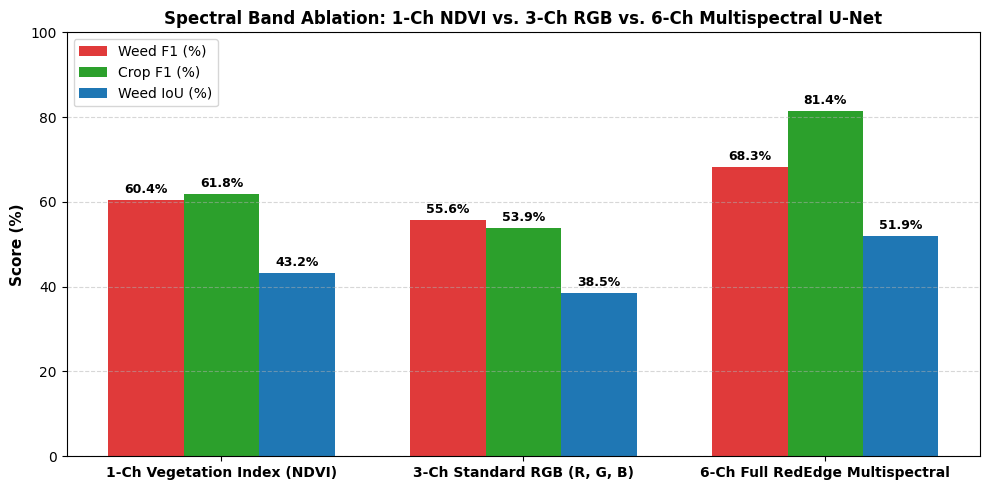

Saved Ablation Table CSV and Plot to: /content/drive/MyDrive/WeedMap_Models


In [8]:
import pandas as pd
import matplotlib.pyplot as plt

ablation_configs = [
    ("1-Ch Vegetation Index (NDVI)", ["NDVI"]),
    ("3-Ch Standard RGB (R, G, B)",  ["R", "G", "B"]),
    ("6-Ch Full RedEdge Multispectral", ["B", "G", "R", "RE", "NIR", "NDVI"])
]

ABLATION_EPOCHS = 15
ablation_results = []

for config_name, ch_list in ablation_configs:
    ch_tag = "_".join(ch_list)
    ckpt_path = os.path.join(SAVE_DIR, f"best_unet_{ch_tag}.pth")

    ds_tr = WeedMapDataset(BASE_DIR, TRAIN_FOLDERS, ch_list, filter_mode=FILTER_MODE, is_train=True)
    ds_te = WeedMapDataset(BASE_DIR, TEST_FOLDERS,  ch_list, filter_mode=FILTER_MODE, is_train=False)
    ld_tr = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
    ld_te = DataLoader(ds_te, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

    net = LightweightUNet(in_channels=len(ch_list), num_classes=3, base_filters=16).to(DEVICE)

    # Reuse our already-trained 6-channel checkpoint if it exists!
    if os.path.exists(ckpt_path) and len(ch_list) == 6:
        print(f"\n[Loaded Existing Best Checkpoint] {config_name} -> {os.path.basename(ckpt_path)}")
        net.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        best_m = evaluate(net, ld_te, DEVICE)
    else:
        print(f"\n[Training Baseline] {config_name} ({len(ch_list)} channels) for {ABLATION_EPOCHS} epochs...")
        opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=ABLATION_EPOCHS)
        best_w_f1 = -1.0
        best_m = None

        for ep in range(1, ABLATION_EPOCHS + 1):
            net.train()
            for bx, by in ld_tr:
                bx, by = bx.to(DEVICE), by.to(DEVICE)
                opt.zero_grad()
                loss = criterion(net(bx), by)
                loss.backward()
                opt.step()
            sched.step()

            m = evaluate(net, ld_te, DEVICE)
            if m["Weed_F1"] > best_w_f1:
                best_w_f1 = m["Weed_F1"]
                best_m = m
                torch.save(net.state_dict(), ckpt_path)
            print(f"  Epoch {ep:02d}/{ABLATION_EPOCHS:02d} | Weed F1: {m['Weed_F1']:.4f} | Crop F1: {m['Crop_F1']:.4f} | IoU: {m['Weed_IoU']:.4f}")

    ablation_results.append({
        "Spectral Configuration": config_name,
        "Channels": len(ch_list),
        "Weed F1 (%)": round(best_m["Weed_F1"] * 100, 2),
        "Crop F1 (%)": round(best_m["Crop_F1"] * 100, 2),
        "Weed IoU (%)": round(best_m["Weed_IoU"] * 100, 2),
        "PR-AUC": round(best_m["PR_AUC"], 4),
        "ROC-AUC": round(best_m["ROC_AUC"], 4),
        "Crop->Weed Risk (%)": round(best_m["Risk_Crop->Weed"] * 100, 2),
        "Weed->Crop Risk (%)": round(best_m["Risk_Weed->Crop"] * 100, 2),
    })

# Print clean comparison table
df_ablation = pd.DataFrame(ablation_results)
print("\n=========================================================================================================")
print(" SPECTRAL ABLATION STUDY RESULTS (Test Field 003)")
print("=========================================================================================================")
print(df_ablation.to_string(index=False))
print("=========================================================================================================\n")

# Save CSV and Bar Chart to Google Drive
csv_path = os.path.join(SAVE_DIR, "spectral_ablation_results.csv")
df_ablation.to_csv(csv_path, index=False)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_ablation))
w = 0.25

b1 = ax.bar(x - w, df_ablation["Weed F1 (%)"], width=w, label="Weed F1 (%)", color="#e03a3a")
b2 = ax.bar(x,     df_ablation["Crop F1 (%)"], width=w, label="Crop F1 (%)", color="#2ca02c")
b3 = ax.bar(x + w, df_ablation["Weed IoU (%)"], width=w, label="Weed IoU (%)", color="#1f77b4")

ax.set_xticks(x)
ax.set_xticklabels(df_ablation["Spectral Configuration"], fontsize=10, fontweight="bold")
ax.set_ylabel("Score (%)", fontsize=11, fontweight="bold")
ax.set_ylim(0, 100)
ax.set_title("Spectral Band Ablation: 1-Ch NDVI vs. 3-Ch RGB vs. 6-Ch Multispectral U-Net", fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
ablation_plot_path = os.path.join(SAVE_DIR, "spectral_ablation_comparison.png")
plt.savefig(ablation_plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved Ablation Table CSV and Plot to: {SAVE_DIR}")

---
### ONNX Export & Interactive Gradio Web Deployment
This block exports the trained 6-channel Lightweight U-Net into a production-ready **ONNX** format for edge deployment, and launches an interactive **Gradio** web application featuring real-time inference on unseen test tiles from Field `003`.

In [6]:
# Install required libraries
!pip install -q gradio onnx onnxscript

import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset
import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --- Restore Missing Variables ---
SAVE_DIR = "/content/drive/MyDrive/WeedMap_Models"
SELECTED_CHANNELS = ["B", "G", "R", "RE", "NIR", "NDVI"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IGNORE_INDEX = 255
BASE_DIR = "/content/dataset/RedEdge"

# --- Restore Model Architecture ---
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.net(x)

class LightweightUNet(nn.Module):
    def __init__(self, in_channels, num_classes=3, base_filters=16):
        super().__init__()
        f = base_filters
        self.enc1 = DoubleConv(in_channels, f)
        self.enc2 = DoubleConv(f, f * 2)
        self.enc3 = DoubleConv(f * 2, f * 4)
        self.enc4 = DoubleConv(f * 4, f * 8)
        self.pool = nn.MaxPool2d(2, 2)
        self.bottleneck = DoubleConv(f * 8, f * 16)
        self.up4  = nn.ConvTranspose2d(f * 16, f * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(f * 16, f * 8)
        self.up3  = nn.ConvTranspose2d(f * 8, f * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(f * 8, f * 4)
        self.up2  = nn.ConvTranspose2d(f * 4, f * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(f * 4, f * 2)
        self.up1  = nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(f * 2, f)
        self.out_conv = nn.Conv2d(f, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([e4, nn.functional.interpolate(self.up4(b), size=e4.shape[2:], mode="bilinear", align_corners=False)], dim=1))
        d3 = self.dec3(torch.cat([e3, nn.functional.interpolate(self.up3(d4), size=e3.shape[2:], mode="bilinear", align_corners=False)], dim=1))
        d2 = self.dec2(torch.cat([e2, nn.functional.interpolate(self.up2(d3), size=e2.shape[2:], mode="bilinear", align_corners=False)], dim=1))
        d1 = self.dec1(torch.cat([e1, nn.functional.interpolate(self.up1(d2), size=e1.shape[2:], mode="bilinear", align_corners=False)], dim=1))
        return self.out_conv(d1)

# --- Restore Dataset Loader for Gradio ---
class WeedMapDataset(Dataset):
    def __init__(self, base_dir, folders, channels):
        self.samples = []
        for folder in folders:
            folder_path = os.path.join(base_dir, folder)
            mask_dir, gt_dir, tile_dir = os.path.join(folder_path, "mask"), os.path.join(folder_path, "groundtruth"), os.path.join(folder_path, "tile")
            for mf in sorted([f for f in os.listdir(mask_dir) if f.lower().endswith(".png")]):
                if np.any(np.array(Image.open(os.path.join(mask_dir, mf))) == 0):
                    self.samples.append(([os.path.join(tile_dir, ch, mf) for ch in channels], os.path.join(mask_dir, mf), os.path.join(gt_dir, f"{folder}_{os.path.splitext(mf)[0]}_GroundTruth_iMap.png")))
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        ch_paths, mask_path, imap_path = self.samples[idx]
        x = np.concatenate([np.transpose(np.array(Image.open(cp), dtype=np.float32)/255.0, (2, 0, 1)) if np.array(Image.open(cp)).ndim == 3 else (np.array(Image.open(cp), dtype=np.float32)/255.0)[np.newaxis, :, :] for cp in ch_paths], axis=0)
        imap, mask = np.array(Image.open(imap_path), dtype=np.int64), np.array(Image.open(mask_path))
        target = np.zeros_like(imap, dtype=np.int64)
        target[imap == 10000], target[imap == 2] = 1, 2
        target[mask > 0] = IGNORE_INDEX
        return torch.from_numpy(x), torch.from_numpy(target)

test_ds = WeedMapDataset(BASE_DIR, ["003"], SELECTED_CHANNELS)

# =====================================================================
# 1. EXPORT TO ONNX (Clean version)
# =====================================================================
onnx_path = os.path.join(SAVE_DIR, "best_unet_6ch_edge.onnx")
dummy_input = torch.randn(1, len(SELECTED_CHANNELS), 360, 480).to(DEVICE)

model_for_export = LightweightUNet(in_channels=len(SELECTED_CHANNELS), num_classes=3, base_filters=16).to(DEVICE)
model_for_export.load_state_dict(torch.load(os.path.join(SAVE_DIR, f"best_unet_B_G_R_RE_NIR_NDVI.pth"), map_location=DEVICE))
model_for_export.eval()

# Let PyTorch handle the opset version automatically to avoid warnings
torch.onnx.export(
    model_for_export, dummy_input, onnx_path,
    export_params=True, do_constant_folding=True,
    input_names=['input_6ch'], output_names=['output_logits'],
    dynamic_axes={'input_6ch': {0: 'batch_size'}, 'output_logits': {0: 'batch_size'}}
)
print(f"✅ ONNX Edge Model exported successfully: {onnx_path}")

# =====================================================================
# 2. GRADIO INTERACTIVE WEB APP
# =====================================================================
def colorize_prediction(arr):
    h, w = arr.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    rgb[arr == 1], rgb[arr == 2], rgb[arr == IGNORE_INDEX] = [0, 220, 0], [255, 30, 30], [40, 40, 40]
    return rgb

def run_segmentation_demo(tile_index):
    x_tensor, y_tensor = test_ds[tile_index]
    with torch.no_grad():
        pred = torch.argmax(model_for_export(x_tensor.unsqueeze(0).to(DEVICE)), dim=1).squeeze(0).cpu().numpy()

    y_np = y_tensor.numpy()
    pred[y_np == IGNORE_INDEX] = IGNORE_INDEX

    x_np = x_tensor.numpy()
    fc = np.stack([x_np[4], x_np[2], x_np[1]], axis=-1)
    fc_display = np.clip(fc * 255.0, 0, 255).astype(np.uint8)

    plt.imsave("temp_ndvi.png", x_np[5], cmap="YlGn")

    return fc_display, plt.imread("temp_ndvi.png")[:, :, :3], colorize_prediction(y_np), colorize_prediction(pred)

# Build without passing theme here to avoid Gradio 6.0 warnings
with gr.Blocks() as app:
    gr.Markdown("# 🌿 Multispectral Precision Agriculture Segmentation")
    gr.Markdown("Interact with the 1.94M-parameter Lightweight U-Net on unseen tiles from Test Field `003`.")
    with gr.Row():
        slider = gr.Slider(minimum=0, maximum=len(test_ds)-1, step=1, label="Select Test Tile Index", value=6)
        btn = gr.Button("Run Inference", variant="primary")
    with gr.Row():
        img_fc = gr.Image(label="Input: False-Color (NIR-R-G)")
        img_ndvi = gr.Image(label="Input: NDVI Channel")
    with gr.Row():
        img_gt = gr.Image(label="Ground Truth (Green=Crop, Red=Weed)")
        img_pred = gr.Image(label="U-Net Prediction")

    btn.click(fn=run_segmentation_demo, inputs=slider, outputs=[img_fc, img_ndvi, img_gt, img_pred])
    slider.change(fn=run_segmentation_demo, inputs=slider, outputs=[img_fc, img_ndvi, img_gt, img_pred])

# Pass theme directly to launch() for Gradio 6.0 compatibility
app.launch(share=True, theme=gr.themes.Soft())

/tmp/ipykernel_886/2378224299.py:99: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `LightweightUNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `LightweightUNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
✅ ONNX Edge Model exported successfully: /content/drive/MyDrive/WeedMap_Models/best_unet_6ch_edge.onnx
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c5e7229fe4d34a63d6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
